# Thực nghiệm — Thử tham số 4 mô hình trên tập A+B

Thử một tham số mới cho mỗi mô hình Logistic Regression, Random Forest, SVM và XGBoost trên tập A+B (38 đặc trưng). Đánh giá bằng cùng Stratified 5-fold CV và CV Macro-F1; đối chiếu với cấu hình mốc và lượt thử trước của nhóm. Không sử dụng tập test.

## 1. Thiết lập tham số thử


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
    ), None
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy ML01_Student_Dropout/feature_b/common.py. Mở đúng dự án rồi chạy lại.")

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-15_ThuThamSo_4MoHinh_AB_Ly"
N_FOLDS = 5
SEED = 42

# Mỗi mô hình thay đổi 1 tham số so với lượt thử A+B của Thương:
# LR: C 1.0 -> 0.2
# RF: max_depth None -> 12
# SVM: gamma 0.001 -> 0.005
# XGB: max_depth 4 -> 5
configs = {
    "Logistic Regression": (
        LogisticRegression,
        {"C": 0.2, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
        True,
    ),
    "Random Forest": (
        RandomForestClassifier,
        {"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 1,
         "class_weight": "balanced", "random_state": SEED, "n_jobs": 1},
        False,
    ),
    "SVM": (
        SVC,
        {"kernel": "rbf", "C": 10, "gamma": 0.005, "class_weight": "balanced"},
        True,
    ),
    "XGBoost": (
        XGBClassifier,
        {"n_estimators": 150, "max_depth": 5, "learning_rate": 0.1,
         "objective": "multi:softprob", "num_class": 3,
         "eval_metric": "mlogloss", "tree_method": "hist",
         "random_state": SEED, "n_jobs": 1},
        False,
    ),
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thiết lập": ", ".join(f"{k}={v!r}" for k, v in params.items()),
        "Chuẩn hóa cột số": "Có" if scale_numeric else "Không",
    }
    for name, (_, params, scale_numeric) in configs.items()
])
display(config_table)


,Mô hình,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,"C=0.2, class_weight='balanced', solver='lbfgs'...",Có
1,Random Forest,"n_estimators=300, max_depth=12, min_samples_le...",Không
2,SVM,"kernel='rbf', C=10, gamma=0.005, class_weight=...",Có
3,XGBoost,"n_estimators=150, max_depth=5, learning_rate=0...",Không


## 2. Huấn luyện và đánh giá bốn mô hình

Dùng cùng 5 fold phân tầng (seed 42) trên `development.csv` để so sánh công bằng.


In [2]:
X_a, X_ab, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows, fold_tables = [], []
for name, (model_class, params, scale_numeric) in configs.items():
    print(f"Đang chạy {name}...")
    model = model_class(**params)
    summary, fold_scores = evaluate(name, model, scale_numeric, "A+B", X_ab, y, folds)
    summary_rows.append(summary)
    fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
fold_results = pd.concat(fold_tables, ignore_index=True)
display(results.round(6))
print(f"Cao nhất: {results.iloc[0]['model']} ({results.iloc[0]['cv_macro_f1']:.6f})")


3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy Logistic Regression...
Đang chạy Random Forest...
Đang chạy SVM...
Đang chạy XGBoost...


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,SVM,A+B,38,0.723082,0.729991,0.626772,0.834748
1,Logistic Regression,A+B,38,0.718329,0.736148,0.615748,0.826259
2,Random Forest,A+B,38,0.713386,0.739666,0.502362,0.880589
3,XGBoost,A+B,38,0.713301,0.772208,0.426772,0.913413


Cao nhất: SVM (0.723082)


## 3. So sánh và lưu kết quả

So điểm của tham số mới với (1) cấu hình mốc A+B trong `experiments/feature_b` và (2) lượt thử A+B trước của nhóm. Các file được lưu riêng vào thư mục `2026-11-15_ThuThamSo_4MoHinh_AB_Ly`.


,Mô hình,A+B mốc,A+B thử trước,A+B thử mới,Mới - mốc,Mới - thử trước
0,Logistic Regression,0.717317,0.711936,0.718329,0.001012,0.006393
1,Random Forest,0.723427,0.722734,0.713386,-0.010041,-0.009348
2,SVM,0.717298,0.701788,0.723082,0.005784,0.021294
3,XGBoost,0.708953,0.717022,0.713301,0.004347,-0.003721


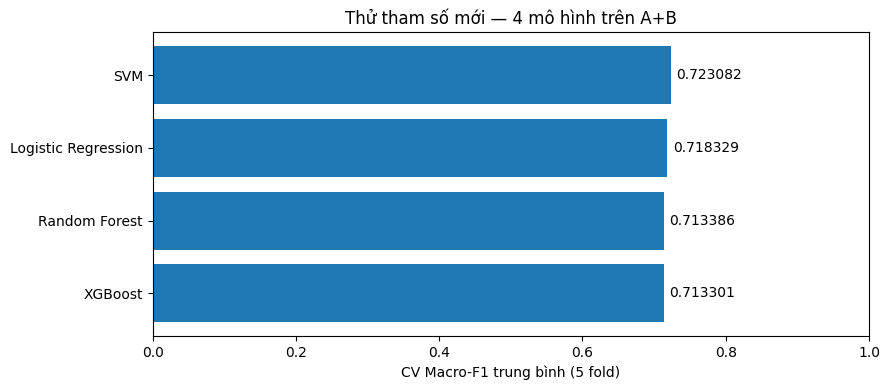

Đã lưu vào: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-15_ThuThamSo_4MoHinh_AB_Ly
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_macro_f1.png


In [3]:
# Điểm từ lượt thử trước của nhóm trên A+B (notebook do Thương chạy).
# Chỉ dùng để đối chiếu, không phải kết quả chạy lại trong notebook hiện tại.
previous_ab = {
    "Logistic Regression": 0.711936,
    "Random Forest": 0.722734,
    "SVM": 0.701788,
    "XGBoost": 0.717022,
}
model_codes = {
    "Logistic Regression": "lr",
    "Random Forest": "rf",
    "SVM": "svm",
    "XGBoost": "xgb",
}
comparison_rows = []
new_scores = results.set_index("model")["cv_macro_f1"]
for name, code in model_codes.items():
    csv_path = project_dir / "experiments" / "feature_b" / f"{code}_a_vs_ab.csv"
    base = pd.read_csv(csv_path)
    base_score = float(base.loc[base["data"].eq("A+B"), "cv_macro_f1"].iloc[0])
    new_score = float(new_scores.loc[name])
    old_trial = previous_ab[name]
    comparison_rows.append({
        "Mô hình": name,
        "A+B mốc": base_score,
        "A+B thử trước": old_trial,
        "A+B thử mới": new_score,
        "Mới - mốc": new_score - base_score,
        "Mới - thử trước": new_score - old_trial,
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))

output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
summary_path = output_dir / "ket_qua_tong_hop.csv"
fold_path = output_dir / "diem_tung_fold.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Ly",
    "Ngày": "15/11/2026",
    "Tập đặc trưng": "A+B",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y), "Số đặc trưng": X_ab.shape[1],
    "Kiểm định chéo": "StratifiedKFold", "Số fold": N_FOLDS,
    "Shuffle": True, "Random state": SEED,
    "Chỉ số": "CV Macro-F1 trung bình",
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh voi moc", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin", index=False)
results.to_csv(summary_path, index=False)
fold_results.to_csv(fold_path, index=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("Thử tham số mới — 4 mô hình trên A+B")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()

print("Đã lưu vào:", output_dir.resolve())
for path in (excel_path, summary_path, fold_path, image_path):
    print(" -", path.name)


## 4. Nhận xét

**Nhận xét:** Sau khi thay đổi siêu tham số trên tập A+B, SVM đạt CV Macro-F1 cao nhất (0.723082), tiếp theo là Logistic Regression (0.718329), Random Forest (0.713386) và XGBoost (0.713301). So với lượt thử trước, SVM và Logistic Regression cải thiện kết quả, trong khi Random Forest và XGBoost giảm nhẹ. Như vậy, cấu hình mới của SVM cho kết quả tốt nhất trong thực nghiệm này.
